### 📊 **PCA Scree Plot — cMD + aMD**

Plots the **first 10 PCA eigenvalues** and **cumulative explained variability** for the combined cMD/aMD ensemble, highlighting the contribution of **PC1 and PC2**.

Saved: ./Plots/cMD_aMD/aMD_cMD_ALL_PCA_Scree.svg


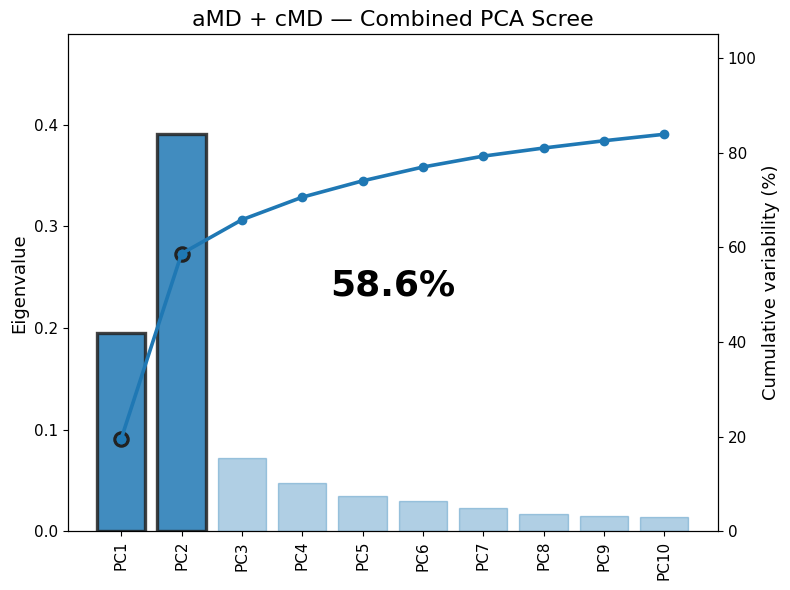

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os, re

# ---------------- paths ----------------
EVEC_FILE = "aMD_cMD_ALL_evecs.dat"
OUT       = "./Plots/cMD_aMD"
os.makedirs(OUT, exist_ok=True)
SAVE_SVG = True

# ---------------- styling ----------------
HIGHLIGHT     = "#222222"
BAR_COLOR     = "#1f78b4"

TITLE_FONT    = 16
LABEL_FONT    = 13
TICK_FONT     = 11
PERCENT_FONT  = 26

# ---------------- load eigenvalues ----------------
def load_evecs(path):
    vals = []
    with open(path) as fh:
        for l in fh:
            if re.match(r"^\s*\d+\s+[-+0-9.Ee]+", l):
                vals.append(float(l.split()[1]))
    v = np.array(vals)
    return 100 * v / v.sum()

v = load_evecs(EVEC_FILE)

pcs = np.arange(1, len(v) + 1)
eig = v / 100
cum = np.cumsum(v)

# ---------------- plot ----------------
fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(pcs[:10], eig[:10],
              color=BAR_COLOR, alpha=0.35,
              edgecolor=BAR_COLOR)

# highlight PC1 + PC2
for i in [0, 1]:
    bars[i].set_edgecolor(HIGHLIGHT)
    bars[i].set_linewidth(2.4)
    bars[i].set_alpha(0.85)

ax.set_ylabel("Eigenvalue", fontsize=LABEL_FONT)
ax.set_ylim(0, max(eig[:10]) * 1.25)
ax.tick_params(labelsize=TICK_FONT)

ax.set_xticks(pcs[:10])
ax.set_xticklabels([f"PC{i}" for i in pcs[:10]],
                   rotation=90, fontsize=TICK_FONT)

# cumulative axis
ax2 = ax.twinx()
ax2.plot(pcs[:10], cum[:10],
         color=BAR_COLOR, lw=2.6, marker="o")
ax2.scatter(pcs[:2], cum[:2],
            s=90, facecolors=BAR_COLOR,
            edgecolors=HIGHLIGHT, linewidths=2.4)

ax2.set_ylabel("Cumulative variability (%)", fontsize=LABEL_FONT)
ax2.set_ylim(0, 105)
ax2.tick_params(labelsize=TICK_FONT)

# PC1 + PC2 annotation
ax2.text(5.5, 52,
         f"{v[0] + v[1]:.1f}%",
         fontsize=PERCENT_FONT, weight="bold",
         ha="center", va="center")

ax.set_title("aMD + cMD — Combined PCA Scree",
             fontsize=TITLE_FONT)

plt.tight_layout()

if SAVE_SVG:
    out = f"{OUT}/aMD_cMD_ALL_PCA_Scree.svg"
    plt.savefig(out, format="svg")
    print("Saved:", out)

plt.show()


### 🎨 **Visualize cMD and aMD Sampling in PCA Space**

Maps the **cMD and aMD trajectories** onto the common **PC1–PC2 conformational landscape** using condition-specific colors for **apo, ligand, peptide, and ligand + peptide** states.

Three views are generated to compare sampling directly:

- **aMD colored / cMD greyed**
- **cMD colored / aMD greyed**
- **all trajectories colored**

⭐ **White stars** mark the starting structures of the cMD trajectories.

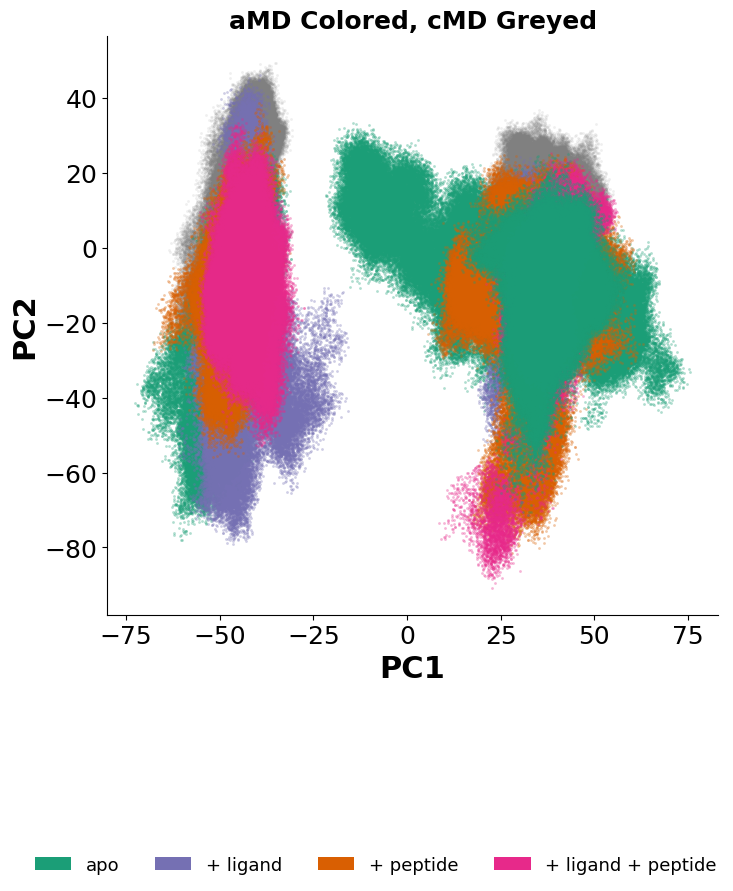

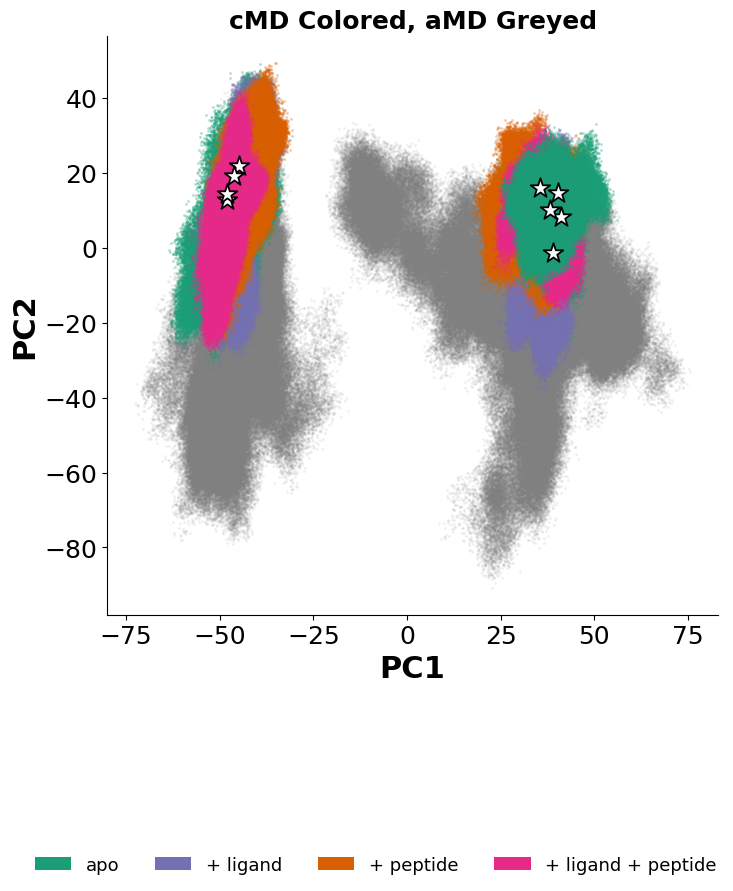

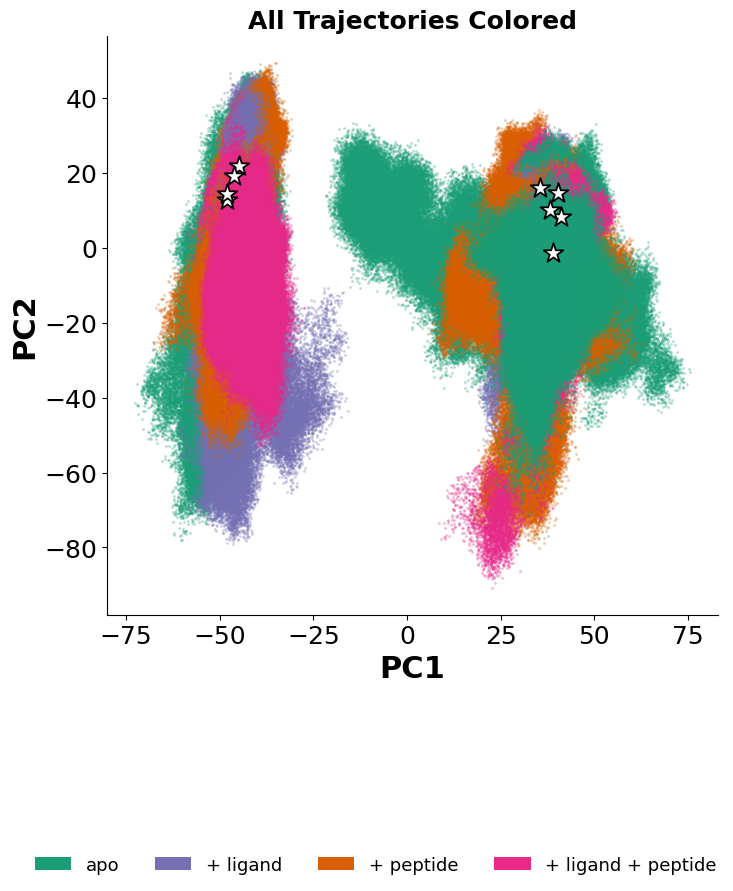

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# =========================
# Styling
# =========================
PC_LABEL_FONT = 22
TICK_FONT     = 18
DOT_SIZE      = 4
STAR_SIZE     = 220

ALPHA_COLOR = 0.35
ALPHA_GREY  = 0.12

# =========================
# Load PCA (from cwd)
# =========================
PCA_PATH = "aMD_cMD_ALL_pca.dat"

data = np.loadtxt(PCA_PATH)
pc1 = data[:, 1]
pc2 = -1.0 * data[:, 2]   # ⬅️ FLIP PC2

# =========================
# Frame bookkeeping
# =========================
REP   = 100_000
COND  = 3 * REP
NSYS  = 9
CYCLE = COND * NSYS       # 2.7M frames per cycle

# =========================
# System order (FIXED)
# =========================
system_order = [
    "6ONI_apo","6ONI_ligand","6ONI_pep_nolig","6ONI_pep_lig",
    "6ONJ_apo","6ONJ_ligand","6ONJ_pep_nolig","6ONJ_pep_lig",
    "3PRG_apo"
]

# =========================
# Condition colors (USER)
# =========================
colors = {
    "apo": "#1b9e77",
    "pep_nolig": "#d95f02",
    "ligand": "#7570b3",
    "pep_lig": "#e7298a",
    "3PRG": "#1b9e77",
    "6ONI_combined": "#7570b3",
    "6ONJ_combined": "#d95f02"
}

def get_cond(sys):
    if "pep_nolig" in sys: return "pep_nolig"
    if "pep_lig"   in sys: return "pep_lig"
    if "ligand"    in sys: return "ligand"
    return "apo"

# =========================
# Plotting function
# =========================
def make_plot(mode, title):
    """
    mode:
      'amd_colored' -> aMD colored, cMD greyed
      'cmd_colored' -> cMD colored, aMD greyed
      'all_colored' -> all colored
    """

    fig, ax = plt.subplots(figsize=(9, 8))

    # ---------- PASS 1: GREY (always underneath) ----------
    for cycle_i, cycle_name in enumerate(["cMD", "aMD"]):

        cycle_offset = cycle_i * CYCLE

        for s, sys in enumerate(system_order):

            cond = get_cond(sys)

            grey_this = (
                (mode == "amd_colored" and cycle_name == "cMD") or
                (mode == "cmd_colored" and cycle_name == "aMD")
            )

            if not grey_this:
                continue

            start = cycle_offset + s * COND
            end   = start + COND
            idx   = np.arange(start, end)

            ax.scatter(pc1[idx], pc2[idx],
                       s=DOT_SIZE,
                       color="grey",
                       alpha=ALPHA_GREY,
                       linewidths=0,
                       zorder=1)

    # ---------- PASS 2: COLORED (on top) ----------
    for cycle_i, cycle_name in enumerate(["cMD", "aMD"]):

        cycle_offset = cycle_i * CYCLE

        for s, sys in enumerate(system_order):

            cond  = get_cond(sys)
            color = colors[cond]

            color_this = (
                mode == "all_colored" or
                (mode == "amd_colored" and cycle_name == "aMD") or
                (mode == "cmd_colored" and cycle_name == "cMD")
            )

            if not color_this:
                continue

            start = cycle_offset + s * COND
            end   = start + COND
            idx   = np.arange(start, end)

            ax.scatter(pc1[idx], pc2[idx],
                       s=DOT_SIZE,
                       color=color,
                       alpha=ALPHA_COLOR,
                       linewidths=0,
                       zorder=3)

            # star only at cMD start
            if cycle_name == "cMD":
                ax.scatter(pc1[start], pc2[start],
                           marker="*", s=STAR_SIZE,
                           facecolor="white",
                           edgecolor="black",
                           linewidth=1.3,
                           zorder=10)

    # ---------- axes ----------
    ax.set_xlabel("PC1", fontsize=PC_LABEL_FONT, fontweight="bold")
    ax.set_ylabel("PC2", fontsize=PC_LABEL_FONT, fontweight="bold")
    ax.set_aspect("equal", "box")
    ax.tick_params(labelsize=TICK_FONT)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_title(title, fontsize=18, weight="bold")

    # ---------- legend ----------
    legend_patches = [
        Patch(facecolor=colors["apo"], label="apo"),
        Patch(facecolor=colors["ligand"], label="+ ligand"),
        Patch(facecolor=colors["pep_nolig"], label="+ peptide"),
        Patch(facecolor=colors["pep_lig"], label="+ ligand + peptide"),
    ]

    fig.legend(handles=legend_patches,
               loc="lower center",
               ncol=4,
               frameon=False,
               fontsize=13,
               bbox_to_anchor=(0.5, -0.12))

    plt.tight_layout(rect=[0, 0.12, 1, 1])
    plt.show()

# =========================
# Generate plots
# =========================
make_plot("amd_colored", "aMD Colored, cMD Greyed")
make_plot("cmd_colored", "cMD Colored, aMD Greyed")
make_plot("all_colored", "All Trajectories Colored")


## 🌐 All-Systems PCA KDE Density — cMD plus aMD 

Visualizes the kernel-density estimate (KDE) of the combined PC1–PC2 conformational
space across **all MD systems cMD and aMD**.

### Processing steps

- Mirrors the **PC2 axis** to maintain consistent orientation across all smulations 

### Plot details

- Scatter plot of PC1 vs PC2, colored by density value.  
- Color bar reports KDE density.  
- Output is saved as a vector graphic.

Saved: ./Plots/cMD_aMD/cMD_aMD_AllSystems_PCA_KDE_density.svg


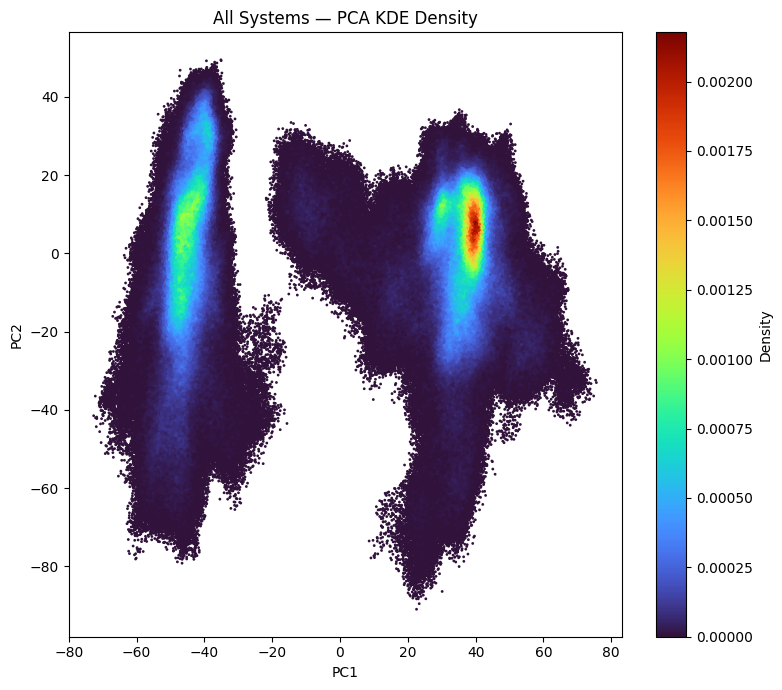

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

BASE = "./"
OUT  = "./Plots/cMD_aMD"
os.makedirs(OUT, exist_ok=True)

SAVE_SVG = True   # ⬅️ toggle svg output

KDE_FILE = f"{BASE}/aMD_cMD_ALL_PC1_PC2_KDE_density.csv"

kde = np.loadtxt(KDE_FILE, delimiter=",", skiprows=1)

pc1  = kde[:, 0]
pc2  = -1.0 * kde[:, 1]   # ⬅️ FLIP PC2
dens = kde[:, 2]

plt.figure(figsize=(8, 7))
sc = plt.scatter(pc1, pc2, c=dens, s=4, cmap="turbo", linewidths=0)

plt.colorbar(sc, label="Density")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("All Systems — PCA KDE Density")

plt.tight_layout()

if SAVE_SVG:
    out = f"{OUT}/cMD_aMD_AllSystems_PCA_KDE_density.svg"
    plt.savefig(out, format="svg")
    print("Saved:", out)

plt.show()
